Iteration: 50 | Best Fitness: 0.0037088489150312624
Iteration: 100 | Best Fitness: 0.0037088489150312624
Iteration: 150 | Best Fitness: 0.0037088489150312624
Iteration: 200 | Best Fitness: 0.0037088489150312624
Iteration: 250 | Best Fitness: 0.0037088489150312624
Iteration: 300 | Best Fitness: 0.0037088489150312624
Iteration: 350 | Best Fitness: 0.0037088489150312624
Iteration: 400 | Best Fitness: 0.0037088489150312624
Iteration: 450 | Best Fitness: 0.0037088489150312624
Iteration: 500 | Best Fitness: 0.0037088489150312624

Final Best Solution: [ 0.06012448 -0.00969001]
Final Best Fitness: 0.0037088489150312624


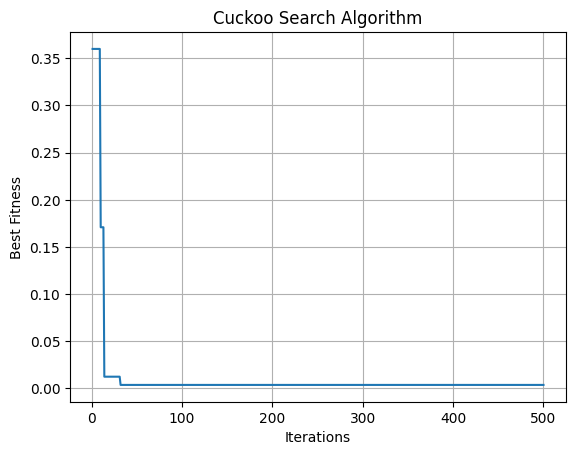

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import math

def objective(x):
    return np.sum(x ** 2)


def levy_flight(dim, beta=1.5):
    sigma = (
        (math.gamma(1 + beta) * math.sin(math.pi * beta / 2)) /
        (math.gamma((1 + beta) / 2) * beta *
         2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, dim)
    v = np.random.normal(0, 1, dim)

    return u / (np.abs(v) ** (1 / beta))


def cuckoo_search(n=25, pa=0.25, iterations=500,
                  dim=2, lower=-5, upper=5, alpha=0.01):

    nests = np.random.uniform(lower, upper, (n, dim))
    fitness = np.array([objective(x) for x in nests])

    best_index = np.argmin(fitness)
    best = nests[best_index].copy()
    best_fitness = fitness[best_index]

    history = []

    for t in range(iterations):

        for i in range(n):

            step = levy_flight(dim)
            new_nest = nests[i] + alpha * step * (nests[i] - best)

            new_nest = np.clip(new_nest, lower, upper)
            new_fitness = objective(new_nest)

            j = np.random.randint(n)

            if new_fitness < fitness[j]:
                nests[j] = new_nest
                fitness[j] = new_fitness

        count = int(pa * n)
        worst = np.argsort(fitness)[-count:]

        nests[worst] = np.random.uniform(
            lower, upper, (count, dim)
        )

        fitness[worst] = np.array([
            objective(x) for x in nests[worst]
        ])

        best_index = np.argmin(fitness)

        if fitness[best_index] < best_fitness:
            best = nests[best_index].copy()
            best_fitness = fitness[best_index]

        history.append(best_fitness)

        if (t + 1) % 50 == 0:
            print("Iteration:", t + 1,
                  "| Best Fitness:", best_fitness)

    return best, best_fitness, history


best, fitness, history = cuckoo_search()

print("\nFinal Best Solution:", best)
print("Final Best Fitness:", fitness)

plt.plot(range(1, 501), history)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Cuckoo Search Algorithm")
plt.grid()
plt.show()
